# Dataset Downloading

In [ ]:

# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES
# TO THE CORRECT LOCATION (/kaggle/input) IN YOUR NOTEBOOK,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

import os
import sys
from tempfile import NamedTemporaryFile
from urllib.request import urlopen
from urllib.parse import unquote, urlparse
from urllib.error import HTTPError
from zipfile import ZipFile
import tarfile
import shutil

CHUNK_SIZE = 40960
DATA_SOURCE_MAPPING = 'heart-disease-prediction-using-logistic-regression:https%3A%2F%2Fstorage.googleapis.com%2Fkaggle-data-sets%2F222487%2F478477%2Fbundle%2Farchive.zip%3FX-Goog-Algorithm%3DGOOG4-RSA-SHA256%26X-Goog-Credential%3Dgcp-kaggle-com%2540kaggle-161607.iam.gserviceaccount.com%252F20241007%252Fauto%252Fstorage%252Fgoog4_request%26X-Goog-Date%3D20241007T210818Z%26X-Goog-Expires%3D259200%26X-Goog-SignedHeaders%3Dhost%26X-Goog-Signature%3D0fd12db219f34829b6293db531c4d0756c038298ebcf2d0f4328e03417d1cc937c4265ecd858f980682bc3691ea949b8723ffd93ce0d3d04939a2a06360de226848637da2ea281f06962a6d902a36801a9c71fd726df0253006be55295d642e74d5fc26cafc5599d57d3abc08b71a2382e76af574b46824d6f7ca45deb64ed5a643dc40296c41bf4822cf356f0d3ef236a6ba8248a915a4b8dc65598a9158a2baf014acdd183e9e8cb476b91c9489be3914daa25309caa7aed126f6908381dd5b2762ff502ed392c055fd9cf2b770b420e35aa42f36a3c7863d167310bd07f3fe97b6622826ab0b651a6d1f13bfeccf6d39f2543fefee03d1d5c61946120b1e0'

KAGGLE_INPUT_PATH='/kaggle/input'
KAGGLE_WORKING_PATH='/kaggle/working'
KAGGLE_SYMLINK='kaggle'

!umount /kaggle/input/ 2> /dev/null
shutil.rmtree('/kaggle/input', ignore_errors=True)
os.makedirs(KAGGLE_INPUT_PATH, 0o777, exist_ok=True)
os.makedirs(KAGGLE_WORKING_PATH, 0o777, exist_ok=True)

try:
  os.symlink(KAGGLE_INPUT_PATH, os.path.join("..", 'input'), target_is_directory=True)
except FileExistsError:
  pass
try:
  os.symlink(KAGGLE_WORKING_PATH, os.path.join("..", 'working'), target_is_directory=True)
except FileExistsError:
  pass

for data_source_mapping in DATA_SOURCE_MAPPING.split(','):
    directory, download_url_encoded = data_source_mapping.split(':')
    download_url = unquote(download_url_encoded)
    filename = urlparse(download_url).path
    destination_path = os.path.join(KAGGLE_INPUT_PATH, directory)
    try:
        with urlopen(download_url) as fileres, NamedTemporaryFile() as tfile:
            total_length = fileres.headers['content-length']
            print(f'Downloading {directory}, {total_length} bytes compressed')
            dl = 0
            data = fileres.read(CHUNK_SIZE)
            while len(data) > 0:
                dl += len(data)
                tfile.write(data)
                done = int(50 * dl / int(total_length))
                sys.stdout.write(f"\r[{'=' * done}{' ' * (50-done)}] {dl} bytes downloaded")
                sys.stdout.flush()
                data = fileres.read(CHUNK_SIZE)
            if filename.endswith('.zip'):
              with ZipFile(tfile) as zfile:
                zfile.extractall(destination_path)
            else:
              with tarfile.open(tfile.name) as tarfile:
                tarfile.extractall(destination_path)
            print(f'\nDownloaded and uncompressed: {directory}')
    except HTTPError as e:
        print(f'Failed to load (likely expired) {download_url} to path {destination_path}')
        continue
    except OSError as e:
        print(f'Failed to load {download_url} to path {destination_path}')
        continue

print('Data source import complete.')


[==================================================] 59801 bytes downloaded
Downloaded and uncompressed: heart-disease-prediction-using-logistic-regression
Data source import complete.


In [ ]:
import numpy as np
import random
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings(action="ignore")

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/heart-disease-prediction-using-logistic-regression/framingham.csv


# Data Cleaning

In [ ]:
data = pd.read_csv("/kaggle/input/heart-disease-prediction-using-logistic-regression/framingham.csv")

In [ ]:
data.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [ ]:
data.tail()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [ ]:
# Null Values
data.isnull().sum()

,0
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50


In [ ]:
data = data.dropna()
data.shape

(3656, 16)

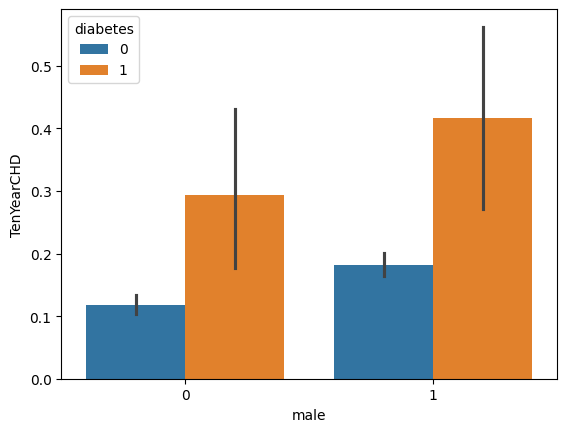

In [ ]:
# Gender, 10-year CHD risk, and diabetes
sns.barplot(x="male", y="TenYearCHD", hue="diabetes", data=data)
plt.show()

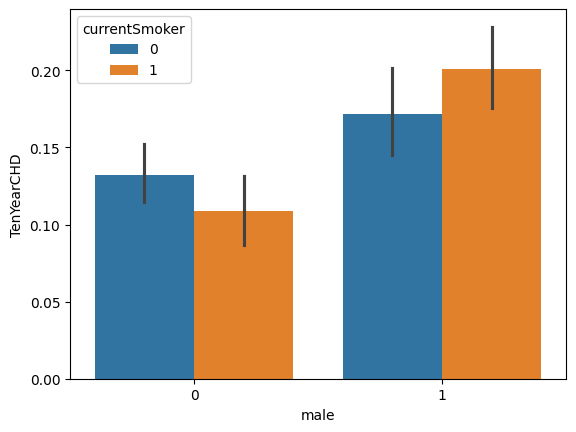

In [ ]:
#  Gender, 10-year CHD risk, and smoking status
sns.barplot(x="male", y="TenYearCHD", hue="currentSmoker", data=data)
plt.show()

# Logistics Regression

In [ ]:
def weightInitialization(n_features):
    w = np.zeros((n_features, 1))
    b = 0
    return w, b

In [ ]:
def sigmoid_activation(z):
    y = 1 / (1 + np.exp(-z))
    return y


In [ ]:
def model_optimize(w, b, X, Y):
    # number of training example
    m = X.shape[0]

    # predictions
    A = sigmoid_activation(np.dot(X, w) + b)

    # cost function
    cost = (-1 / m) * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))

    # Gradients
    dw = (1 / m) * np.dot(X.T, (A - Y))
    db = (1 / m) * np.sum(A - Y)

    grads = {"dw": dw, "db": db}
    return grads, cost


In [ ]:
def model_optimize_reg(w, b, X, Y, reg=None, lambd=0.1):
    #number of training sample
    m = X.shape[0]

    #using sigmoid activation
    A = sigmoid_activation(np.dot(X, w) + b)

    #Cost function with regularization
    cost = (-1 / m) * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))

    if reg == "l1":
        cost += (lambd / (2 * m)) * np.sum(np.abs(w))
    elif reg == "l2":
        cost += (lambd / (2 * m)) * np.sum(np.abs(w))


    #Gradients with regularization
    dw = (1 / m) * np.dot(X.T, (A - Y))
    db = (1 / m) * np.sum(A - Y)

    if reg == "l1":
        dw += (lambd / m) * np.sign(w)
    elif reg == "l2":
        dw += (lambd / m) * w

    grads = {"dw": dw, "db": db}

    return grads, cost

In [ ]:
# def model_fit(w, b, X, Y, learning_rate, no_iterations):
#     costs = []
#     for i in range(no_iterations):
#         grads, cost = model_optimize(w, b, X, Y)
#         dw = grads["dw"]
#         db = grads["db"]
#         w -= learning_rate * dw
#         b -= learning_rate * db
#         if i % 10 == 0:
#             costs.append(cost)
#     coeff = {"w": w, "b": b}
#     return coeff, costs


def model_fit(w, b, X_train, Y_train, X_test, Y_test, learning_rate, no_iterations):
    costs = []
    train_accuracies = []
    test_accuracies = []

    for i in range(no_iterations):
        # Forward and backward propagation to get gradients and cost
        grads, cost = model_optimize(w, b, X_train, Y_train)
        dw = grads["dw"]
        db = grads["db"]

        # Update weights and bias
        w -= learning_rate * dw
        b -= learning_rate * db

        # Every 10 iterations, log cost and accuracies
        if i % 10 == 0:
            costs.append(cost)

            # Predict for train and test sets
            train_predictions = np.dot(X_train, w) + b > 0.5  # Assuming sigmoid activation for binary classification
            test_predictions = np.dot(X_test, w) + b > 0.5

            # Calculate accuracies
            train_accuracy = np.mean(train_predictions == Y_train) * 100
            test_accuracy = np.mean(test_predictions == Y_test) * 100

            train_accuracies.append(train_accuracy)
            test_accuracies.append(test_accuracy)

    # Return model parameters, costs, and accuracies
    coeff = {"w": w, "b": b}
    return coeff, costs, train_accuracies, test_accuracies


# Helping Functions

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

def plot_training_vs_testing_accuracy(train_accuracies, test_accuracies):
    """
    Plots the training accuracy vs testing accuracy over epochs.

    Parameters:
    - train_accuracies: list of training accuracies over epochs.
    - test_accuracies: list of testing accuracies over epochs.
    """

    epochs = range(1, len(train_accuracies) + 1)

    plt.plot(epochs, train_accuracies, 'b-', label='Training Accuracy')
    plt.plot(epochs, test_accuracies, 'r-', label='Testing Accuracy')

    plt.title('Training vs. Testing Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns


def plot_confusion_matrix(Y_test, Y_pred):

    cm = confusion_matrix(Y_test, Y_pred)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', cbar=False)

    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.show()

# Test Train Split

In [ ]:
# Convert TenYearCHD column to 0 and 1
data['TenYearCHD'] = data['TenYearCHD'].astype('category')
data['TenYearCHD'] = data['TenYearCHD'].cat.codes
data


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4231,1,58,3.0,0,0.0,0.0,0,1,0,187.0,141.0,81.0,24.96,80.0,81.0,0
4232,1,68,1.0,0,0.0,0.0,0,1,0,176.0,168.0,97.0,23.14,60.0,79.0,1
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0


In [ ]:
# Define target variable (y) and features (x_data)
x_data = data.drop(columns = 'TenYearCHD')
y = data['TenYearCHD']


In [ ]:
# Normalize the feature data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_data_scaled = scaler.fit_transform(x_data)
x_data_scaled

array([[ 1.11982472, -1.23335117,  1.97575158, ...,  0.29168785,
         0.35633992, -0.20312694],
       [-0.8929969 , -0.41559058,  0.01979497, ...,  0.7246142 ,
         1.60828949, -0.24495595],
       [ 1.11982472, -0.1819447 , -0.95818334, ..., -0.10926099,
        -0.06097661, -0.49592996],
       ...,
       [ 1.11982472,  0.05170118, -0.95818334, ...,  0.04570696,
        -0.81214636,  0.17333408],
       [ 1.11982472,  0.16852412,  0.99777327, ..., -1.49413337,
        -0.89560966, -0.57958797],
       [-0.8929969 ,  0.28534706,  0.01979497, ..., -1.06120701,
         0.35633992,  1.05174313]])

In [ ]:
# Train-test split
x_train, x_test, y_train, y_test = train_test_split(x_data_scaled, y, test_size=0.2, random_state=42)

In [ ]:
# No need to reshape x_train and x_test; they should remain 2D
# Only y_train and y_test need to be 1D
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

# Fitting Model

In [ ]:
# Initialize weights and bias
n_features = x_train.shape[1] #number of features
w, b = weightInitialization(n_features)

In [ ]:
# Train the model
learning_rate = 0.01
no_iterations = 500
coeff, costs, train_accuracies, test_accuracies = model_fit(w, b, x_train, y_train, x_test, y_test, learning_rate, no_iterations)


# Visualization

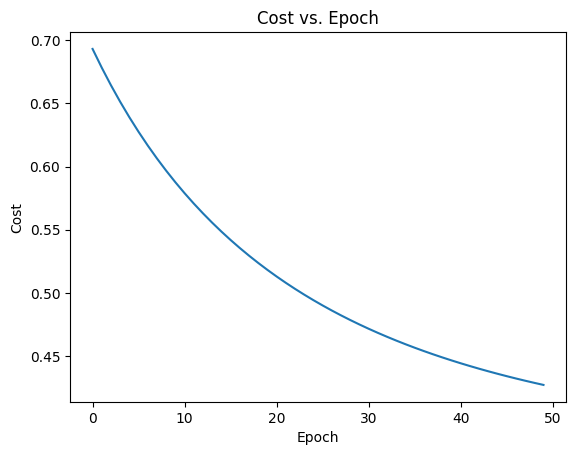

In [ ]:
# Cost vs Epoch Curve
plt.plot(range(len(costs)), costs)
plt.title('Cost vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.show()

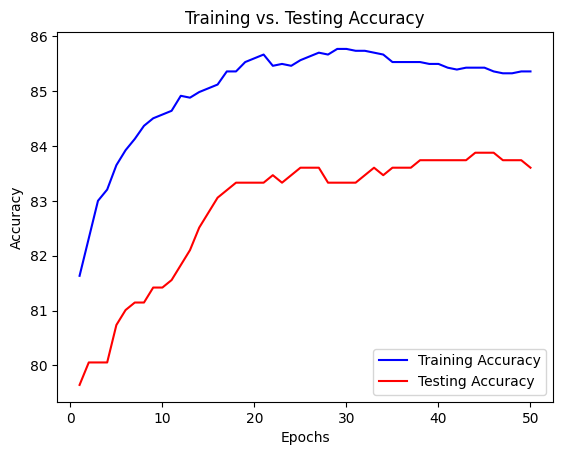

In [ ]:
# test vs train accuracy
plot_training_vs_testing_accuracy(train_accuracies, test_accuracies)

# Predicting

In [ ]:
# Prediction function using the learned weights and bias
def model_predict(w, b, X):
    # complete the prediction function
    z = np.dot(X, w) + b

    y_pred = sigmoid_activation(z)

    y_pred = (y_pred > 0.5).astype(int)

    return y_pred

# Get predictions on the test set
y_pred = model_predict(coeff['w'], coeff['b'], x_test)



In [ ]:
# Using smaller portions of the training data to see how accuracy changes


# Calculating Accuracy

In [ ]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 83.33%


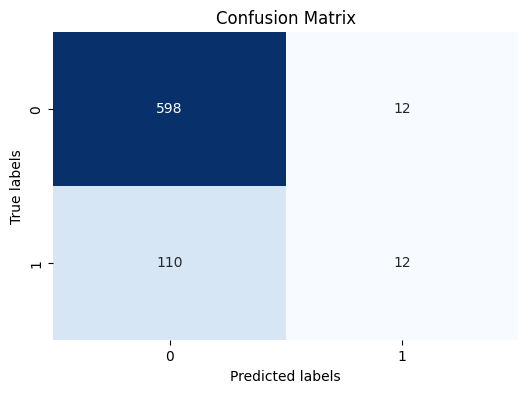

In [ ]:
# Visualize the confusion matrix
plot_confusion_matrix(y_test, y_pred)

In [ ]:
# find other accuracy metrics

# Sklearn Models

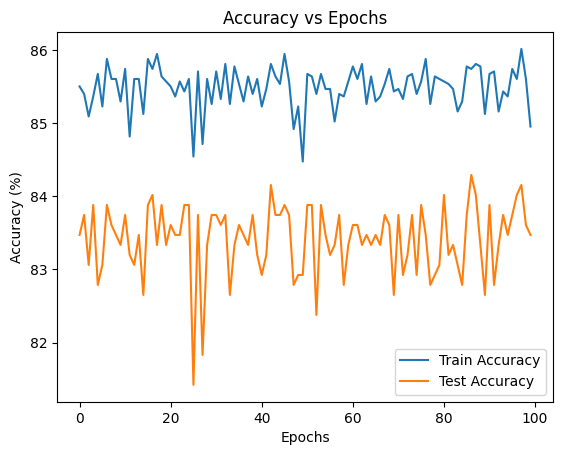

Confusion Matrix:



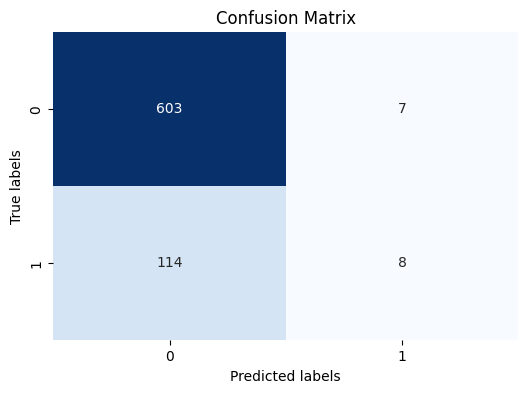

In [ ]:
# use the models from sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

def logistic_regression_model(x_train, y_train, x_test, y_test, epochs=100):
    # Store train and test accuracies for plotting
    train_accuracies = []
    test_accuracies = []

    # Initialize logistic regression model with 'saga' solver
    model = LogisticRegression(max_iter=1, solver='saga', penalty=None, warm_start=True)

    for epoch in range(epochs):
        # Incrementally train the model over the epochs
        model.fit(x_train, y_train)

        # Predict on both train and test sets
        train_predictions = model.predict(x_train)
        test_predictions = model.predict(x_test)

        # Calculate accuracies for train and test sets
        train_accuracy = accuracy_score(y_train, train_predictions) * 100
        test_accuracy = accuracy_score(y_test, test_predictions) * 100

        # Append to lists for graphing later
        train_accuracies.append(train_accuracy)
        test_accuracies.append(test_accuracy)

    # Plot accuracy vs epochs
    plt.plot(range(epochs), train_accuracies, label='Train Accuracy')
    plt.plot(range(epochs), test_accuracies, label='Test Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.title('Accuracy vs Epochs')
    plt.legend()
    plt.show()

    # Get confusion matrix for test set
    final_predictions = model.predict(x_test)
    conf_matrix = confusion_matrix(y_test, final_predictions)

    print("Confusion Matrix:\n")
    plot_confusion_matrix(y_test, final_predictions)
    return model

model = logistic_regression_model(x_train, y_train, x_test, y_test, epochs=100)
# logistics regression, decision trees, naive bayes